<a href="https://colab.research.google.com/github/arabadzhyanzhela-collab/github-lab-2/blob/main/01_Fraude_con_tarjeta.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#  Miniapp 1 · ¿Esta compra es un fraude?

## Qué construimos
Un **detector de compras sospechosas** para un banco. El problema: de cada 100 compras, solo **1 o 2** son fraude.

Al final del cuaderno sabrás:
1. Por qué un modelo que **«acierta el 98 %» puede ser inútil**.
2. Qué métricas mirar cuando una clase es rara (**AUC**, **AP**, **matriz de confusión**).
3. Cómo elegir el **umbral de aviso con euros**, no con intuición.
4. Cómo convertir el modelo en una **pequeña app** que revisa una compra.

## Datos
`fraude_tarjeta.csv`: 20 000 compras **inventadas**, con un **1,5 % de fraudes**.

| Columna | Qué significa |
|---|---|
| `importe` | euros de la compra |
| `hora` | hora del día (0–23) |
| `distancia_casa_km` | distancia entre la compra y el domicilio del cliente |
| `es_extranjero` | 1 = compra fuera del país |
| `comercio` | tipo de comercio (texto: supermercado, electrónica…) |
| `compras_ultima_hora` | cuántas compras hizo esa tarjeta en la última hora |
| `antiguedad_tarjeta_meses` | meses desde que se emitió la tarjeta |
| `pago_online` | 1 = compra por internet |
| **`es_fraude`** | **objetivo**: 1 = fraude, 0 = normal |

##  Índice
0. Preparar el entorno
1. Carga y cuenta
2. Separar train / examen conservando la proporción
3. La trampa: el modelo que nunca avisa
4. Comparar modelos con las métricas buenas
5. Elegir el umbral con euros
6. El examen (una sola vez)
7. Tu app
8. Extras  (con solución)
9. Hoja del equipo
10. Prueba


---
## 0️⃣ Preparar el entorno: librerías

Antes de empezar importamos las herramientas. Para qué sirve cada bloque:

- **pandas / numpy** → tablas y cálculos.
- **matplotlib** → gráficos.
- **model_selection** → separar datos (`train_test_split`) y hacer **validación cruzada** (`cross_val_score`, `cross_val_predict`, `StratifiedKFold`).
- **ColumnTransformer + Pipeline** → preparar columnas numéricas y de texto **dentro** del modelo, para no hacer trampas con los datos del examen.
- **Modelos**: `DummyClassifier` (el «tonto»), `LogisticRegression`, `KNeighborsClassifier`, `GaussianNB`.
- **metrics** → matriz de confusión, AUC, AP, precisión y sensibilidad (*recall*).

# **Nota:** `warnings.filterwarnings("ignore")` oculta avisos que no afectan al resultado, para que la salida quede limpia.

In [2]:
import warnings; warnings.filterwarnings("ignore")
import pandas as pd, numpy as np, matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score, cross_val_predict, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import confusion_matrix, roc_auc_score, average_precision_score, precision_score, recall_score

print("✅ Librerías cargadas")

✅ Librerías cargadas


---
## 1️⃣ Carga y cuenta: ¿cómo de desiguales son las clases?

Leemos el CSV directamente desde GitHub y contamos cuántos fraudes hay.

Después comparamos la **media** de algunas columnas entre compras normales (`0`) y fraudes (`1`). Así vemos, antes de modelar, **qué variables delatan** un fraude.

 # **Nota:** `df["es_fraude"].mean()` da directamente el **porcentaje de fraudes**, porque la columna solo tiene 0 y 1.

In [3]:
URL = "https://raw.githubusercontent.com/cCoolBoox/IFCD107-alumnado/main/datos/fraude_tarjeta.csv"
df = pd.read_csv(URL)

print("Filas y columnas:", df.shape)
print("Fraudes:", int(df["es_fraude"].sum()), f"({df['es_fraude'].mean():.2%})")
df.head()

Filas y columnas: (20000, 9)
Fraudes: 309 (1.54%)


,importe,hora,distancia_casa_km,es_extranjero,comercio,compras_ultima_hora,antiguedad_tarjeta_meses,pago_online,es_fraude
0,70.34,16,0.7,0,gasolinera,1,41,0,0
1,24.45,17,22.2,0,moda_online,0,17,1,0
2,56.89,20,13.8,0,moda_online,1,32,0,0
3,83.35,16,17.1,0,moda_online,0,14,0,0
4,25.65,20,5.8,0,juegos_online,0,35,1,0


In [4]:
# Media de algunas columnas para compras normales (0) y fraudes (1)
df.groupby("es_fraude")[["importe", "distancia_casa_km", "compras_ultima_hora", "antiguedad_tarjeta_meses"]].mean().round(1)

,importe,distancia_casa_km,compras_ultima_hora,antiguedad_tarjeta_meses
es_fraude,,,,
0,59.5,21.9,0.5,42.1
1,141.6,61.0,1.0,23.6


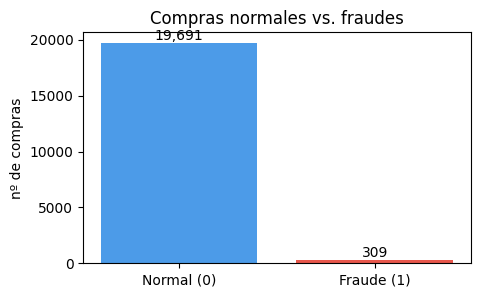

In [5]:
# Gráfico rápido: lo pequeña que es la clase "fraude"
conteo = df["es_fraude"].value_counts().sort_index()
plt.figure(figsize=(5, 3))
plt.bar(["Normal (0)", "Fraude (1)"], conteo.values, color=["#4C9BE8", "#E8574C"])
for i, v in enumerate(conteo.values):
    plt.text(i, v, f"{v:,}", ha="center", va="bottom")
plt.title("Compras normales vs. fraudes"); plt.ylabel("nº de compras"); plt.show()

### Qué deberías ver
- **20 000 compras, 309 fraudes (1,54 %)**.
- Los fraudes son **más caros** (≈ 142 € frente a ≈ 60 €), ocurren **más lejos de casa**, con **más compras seguidas** y en **tarjetas más nuevas**.

# **Interpretación:** la barra roja casi no se ve. Esto es un problema de **clases desequilibradas**: cualquier modelo «perezoso» puede sacar buena nota diciendo siempre «normal».

---
## 2️⃣ Separar train / examen conservando la proporción (`stratify`)

- **`train` (75 %)**: con lo que el modelo aprende y con lo que elegimos el umbral.
- **Examen (25 %)**: se guarda en un cajón y se usa **una sola vez** al final.

# **¿Por qué `stratify=y`?** Con solo 309 fraudes, un reparto al azar podría dejar el examen con muy pocos. `stratify` garantiza el **mismo 1,5 %** en las dos partes.

También preparamos la función `con_modelo(m)`, que envuelve cualquier modelo en un **Pipeline**:
- `StandardScaler` → pone las columnas numéricas en la misma escala (importante para logística y k-NN).
- `OneHotEncoder` → convierte `comercio` (texto) en columnas 0/1.

# **Nota:** el preprocesado va **dentro** del Pipeline para que, en la validación cruzada, la escala se calcule solo con los datos de entrenamiento de cada pliegue (sin «espiar»).

In [6]:
y = df["es_fraude"]
X = df.drop(columns="es_fraude")

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)
print("Fraudes en train:", int(y_tr.sum()), "· en el examen:", int(y_te.sum()))

numericas = [c for c in X.columns if c != "comercio"]   # todas menos la de texto

def con_modelo(m):
    # Prepara columnas (escala + one-hot) y después aplica el modelo m
    prep = ColumnTransformer([("n", StandardScaler(), numericas),
                              ("c", OneHotEncoder(handle_unknown="ignore"), ["comercio"])])
    return Pipeline([("prep", prep), ("modelo", m)])

Fraudes en train: 232 · en el examen: 77


### Qué deberías ver
**232 fraudes en `train`** y **77 en el examen**: la proporción se mantiene.

# **Nota:** añadimos `handle_unknown="ignore"` al `OneHotEncoder` para que la app no falle si un día le pasamos un comercio que no estaba en los datos.

---
## 3 La trampa: un modelo que dice **siempre «no es fraude»**

`DummyClassifier(strategy="most_frequent")` no mira los datos: responde siempre la clase más común (0 = normal).

Lo evaluamos con **validación cruzada estratificada de 5 pliegues** (`StratifiedKFold`): se divide `train` en 5 trozos, se entrena con 4 y se evalúa con el 5.º, rotando. La nota es la **media** de las 5 rondas.

# **Pregunta antes de ejecutar:** ¿qué *accuracy* (precisión global) crees que sacará?

In [7]:
cv = StratifiedKFold(5, shuffle=True, random_state=42)

tonto = con_modelo(DummyClassifier(strategy="most_frequent"))
acc = cross_val_score(tonto, X_tr, y_tr, cv=cv, scoring="accuracy").mean()
print(f"El modelo que nunca avisa acierta el {acc:.1%}... y no detecta ni un fraude")

El modelo que nunca avisa acierta el 98.5%... y no detecta ni un fraude


###  Qué deberías ver
El modelo tonto acierta el **98,5 %**.

# **Moraleja:** la *accuracy* **engaña** cuando una clase es rara. Un 98,5 % suena genial, pero el banco perdería **todos** los fraudes. Necesitamos otras métricas.

---
## 4 Comparar modelos con las métricas buenas

Comparamos 5 modelos con tres métricas (todas con validación cruzada en `train`):

| Métrica | Qué mide | Valor del azar |
|---|---|---|
| **Precisión global** (*accuracy*) | % de aciertos totales | ≈ 98,5 % (¡engaña!) |
| **AUC** (área bajo la curva ROC) | ¿pone el modelo a los fraudes por encima de las compras normales? | 0,50 |
| **AP** (*average precision*, área bajo la curva precisión–recall) | calidad de los avisos centrándose **solo en los fraudes** | ≈ 0,015 (el % de fraudes) |

# **Nota:** con tan pocos fraudes, la **AP** es la más exigente y la más informativa: no se deja impresionar por los miles de compras normales bien clasificadas.

# **«Logística con pesos»** (`class_weight="balanced"`) da más importancia a cada fraude durante el entrenamiento → avisa mucho más.

# Esta celda tarda unos segundos (5 modelos × 3 métricas × 5 pliegues).

In [8]:
modelos = {"Siempre «no» (tonto)": DummyClassifier(strategy="most_frequent"),
           "Logística":            LogisticRegression(max_iter=1000),
           "Logística con pesos":  LogisticRegression(max_iter=1000, class_weight="balanced"),
           "k-NN (k=15)":          KNeighborsClassifier(15),
           "Naive Bayes":          GaussianNB()}

filas = {}
for nombre, m in modelos.items():
    p = con_modelo(m)
    filas[nombre] = {"precisión global": cross_val_score(p, X_tr, y_tr, cv=cv, scoring="accuracy").mean(),
                     "AUC":              cross_val_score(p, X_tr, y_tr, cv=cv, scoring="roc_auc").mean(),
                     "AP":               cross_val_score(p, X_tr, y_tr, cv=cv, scoring="average_precision").mean()}

tabla = pd.DataFrame(filas).T.round(3)
tabla

,precisión global,AUC,AP
Siempre «no» (tonto),0.985,0.500,0.015
Logística,0.988,0.928,0.542
Logística con pesos,0.884,0.932,0.475
k-NN (k=15),0.986,0.821,0.429
Naive Bayes,0.967,0.908,0.317


### Qué deberías ver
- **Tonto:** 98,5 % · AUC **0,50** · AP **0,015** → no sabe nada.
- **Logística:** 98,8 % · AUC **0,93** · AP **0,54** → la mejor.
- **Logística con pesos:** la precisión global **baja a ≈ 88 %** (avisa muchísimo) y la AP a ≈ 0,48.
- **k-NN:** AUC ≈ 0,82. **Naive Bayes:** AUC ≈ 0,91 · AP ≈ 0,32.

# **Interpretación:** fíjate en que la precisión global de todos es parecida (88–99 %), pero el **AUC** y la **AP** sí separan claramente los modelos útiles de los inútiles. Elegimos la **logística** para seguir.


## 5 El umbral con euros 💶

El modelo no dice «fraude / no fraude»: da una **probabilidad**. Nosotros decidimos a partir de qué probabilidad **avisamos** (el **umbral**). Por defecto es 0,50, pero… ¿es el mejor?

### Los costes de cada error
| Error | Qué pasa | Coste |
|---|---|---|
| **Fraude que se escapa** (falso negativo) | el banco pierde el dinero | **el importe de la compra** |
| **Falsa alarma** (falso positivo) | hay que llamar al cliente | **3 €** |

### Qué hace el código
1. `cross_val_predict` → probabilidades «honestas» para cada compra de `train` (cada una predicha por un modelo que **no la vio** al entrenar).
2. `coste(...)` → suma euros perdidos + molestias para un umbral dado.
3. Probamos umbrales de 0,01 a 0,89 y nos quedamos con el **más barato**.

# **Nota:** elegimos el umbral **solo con `train`**. Si lo eligiéramos mirando el examen, la nota final sería tramposa.

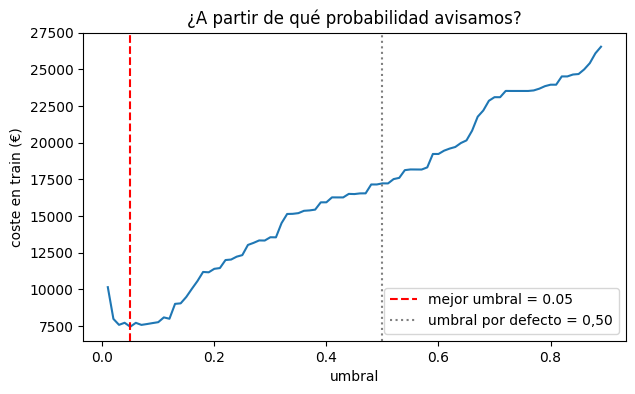

Umbral con menor coste: 0.05
Con 0,50 por defecto el coste era 17,228 € frente a 7,451 €


In [9]:
logistica = con_modelo(LogisticRegression(max_iter=1000))
proba_cv = cross_val_predict(logistica, X_tr, y_tr, cv=cv, method="predict_proba")[:, 1]   # prob. de fraude

def coste(y_real, proba, importes, umbral, falsa_alarma=3):
    aviso = proba >= umbral                                   # True = avisamos
    perdido = importes[(y_real == 1) & ~aviso].sum()          # fraudes sin aviso → perdemos el importe
    molestias = falsa_alarma * ((y_real == 0) & aviso).sum()  # avisos a compras normales → 3 € cada uno
    return perdido + molestias

umbrales = np.arange(0.01, 0.9, 0.01)
costes = [coste(y_tr.values, proba_cv, X_tr["importe"].values, u) for u in umbrales]
mejor = umbrales[int(np.argmin(costes))]

plt.figure(figsize=(7, 4))
plt.plot(umbrales, costes)
plt.axvline(mejor, color="red", ls="--", label=f"mejor umbral = {mejor:.2f}")
plt.axvline(0.5, color="gray", ls=":", label="umbral por defecto = 0,50")
plt.xlabel("umbral"); plt.ylabel("coste en train (€)"); plt.legend()
plt.title("¿A partir de qué probabilidad avisamos?"); plt.show()

print(f"Umbral con menor coste: {mejor:.2f}")
print(f"Con 0,50 por defecto el coste era {coste(y_tr.values, proba_cv, X_tr['importe'].values, 0.5):,.0f} € "
      f"frente a {min(costes):,.0f} €")

###  Qué deberías ver
- El mejor umbral sale **≈ 0,05** (¡no 0,50!).
- En `train` el coste pasa de **≈ 17 200 €** (umbral 0,50) a **≈ 7 500 €**.

# **¿Por qué tan bajo?** Dejar pasar un fraude cuesta de media ≈ 142 €; una falsa alarma, 3 €. Sale a cuenta **avisar aunque solo estemos un poco seguros**. La curva sube rápido hacia la derecha porque se escapan cada vez más fraudes.

---
## 6 El examen: **una sola vez**, con el umbral ya elegido

Ahora sí:
1. Entrenamos la logística con **todo `train`**.
2. Calculamos probabilidades para el **examen**.
3. Aplicamos el umbral elegido en el paso 5 (sin tocarlo).

### Cómo leer la matriz de confusión
|  | Predice normal | Predice fraude (aviso) |
|---|---|---|
| **Real normal** | VN (verdadero negativo) ✅ | FP (falsa alarma) 📞 |
| **Real fraude** | FN (fraude que se escapa) 💸 | VP (fraude detectado) 🎯 |

# **Nota:** `.ravel()` aplana la matriz 2×2 en el orden `vn, fp, fn, vp`.

In [10]:
final = logistica.fit(X_tr, y_tr)
proba = final.predict_proba(X_te)[:, 1]
aviso = proba >= mejor

vn, fp, fn, vp = confusion_matrix(y_te, aviso).ravel()
print(f"Fraudes detectados: {vp} de {vp + fn} · falsas alarmas: {fp} · fraudes que se escapan: {fn}")
print(f"Precisión de los avisos: {precision_score(y_te, aviso):.1%} · Sensibilidad (recall): {recall_score(y_te, aviso):.1%}")
print(f"AUC {roc_auc_score(y_te, proba):.3f} · AP {average_precision_score(y_te, proba):.3f}")

sin_modelo = X_te["importe"].values[y_te.values == 1].sum()
con_mod = coste(y_te.values, proba, X_te["importe"].values, mejor)
print(f"Sin modelo se pierden {sin_modelo:,.0f} € · con el modelo {con_mod:,.0f} € (incluidas las molestias)")

Fraudes detectados: 52 de 77 · falsas alarmas: 212 · fraudes que se escapan: 25
Precisión de los avisos: 19.7% · Sensibilidad (recall): 67.5%
AUC 0.935 · AP 0.534
Sin modelo se pierden 11,151 € · con el modelo 3,164 € (incluidas las molestias)


In [11]:
# Matriz de confusión en forma de tabla, más fácil de leer
pd.DataFrame([[vn, fp], [fn, vp]],
             index=["Real: normal", "Real: fraude"],
             columns=["Predice: normal", "Predice: fraude (aviso)"])

,Predice: normal,Predice: fraude (aviso)
Real: normal,4711,212
Real: fraude,25,52


###  Qué deberías ver
- Detectas **52 de 77** fraudes, con **212 falsas alarmas** y **25 fraudes** que se escapan.
- Pérdida **≈ 3 200 €** (molestias incluidas) frente a **≈ 11 150 €** sin modelo → ahorro de unos **8 000 €**.

# **Cuidado:** solo hay 77 fraudes en el examen; uno más o uno menos mueve mucho los porcentajes. **No te fíes de los decimales.**

---
## 7 Tu app: revisar **una compra**

Función `revisar(...)`:
1. Recibe los datos de **una** compra.
2. Los mete en una tabla de 1 fila con **los mismos nombres de columna** que el entrenamiento.
3. Calcula la probabilidad de fraude con el modelo `final`.
4. Si supera el umbral `mejor` → **⚠️ AVISAR**; si no → **✅ normal**.

# **Nota:** no hace falta escalar ni codificar a mano: el **Pipeline** ya lo hace por dentro.

In [12]:
def revisar(importe, hora, distancia_casa_km, es_extranjero, comercio,
            compras_ultima_hora, antiguedad_tarjeta_meses, pago_online):
    fila = pd.DataFrame([dict(importe=importe, hora=hora, distancia_casa_km=distancia_casa_km,
                              es_extranjero=es_extranjero, comercio=comercio,
                              compras_ultima_hora=compras_ultima_hora,
                              antiguedad_tarjeta_meses=antiguedad_tarjeta_meses, pago_online=pago_online)])
    p = final.predict_proba(fila)[0, 1]
    return f"{'⚠️ AVISAR' if p >= mejor else '✅ normal'} · probabilidad de fraude {p:.1%}"

print(revisar(35, 13, 4, 0, "supermercado", 1, 40, 0))       # compra cotidiana
print(revisar(950, 3, 800, 1, "electronica", 5, 2, 1))       # muy sospechosa
print(revisar(120, 23, 60, 1, "juegos_online", 2, 6, 1))     # dudosa

✅ normal · probabilidad de fraude 0.1%
⚠️ AVISAR · probabilidad de fraude 100.0%
⚠️ AVISAR · probabilidad de fraude 30.5%


###  Qué deberías ver
- Supermercado a mediodía → ≈ **0,1 %** ✅
- 950 € en electrónica, en el extranjero, de madrugada, tarjeta nueva → ≈ **100 %** ⚠️
- Juegos online de noche → ≈ **30 %** → como supera 0,05, **avisa** ⚠️

# **Nota:** comercios válidos (los que vio el modelo):

In [13]:
print(sorted(df["comercio"].unique()))

['electronica', 'gasolinera', 'juegos_online', 'moda_online', 'restaurante', 'supermercado', 'viajes']


---
## 8 Extras

1. Cambia el coste de una falsa alarma a **20 €**: ¿sube o baja el umbral?, ¿por qué?
2. Prueba el umbral **0,5** en el examen y compáralo con el tuyo.
3. ¿Qué cuenta más: avisar de más o de menos? Escribe cómo se lo explicarías a un **directivo del banco**.

> 🙈 **Intenta cada uno antes de mirar la solución** de las celdas siguientes. Las cifras pueden variar un poco según la versión de las librerías: lo importante es la **conclusión**.

### Extra 1 · Falsa alarma a 20 €
Repetimos la búsqueda del umbral cambiando el último parámetro de `coste` y comparamos 3 € con 20 €. Después miramos el examen con cada umbral, contando las falsas alarmas a 20 €.

In [14]:
umbral_por_coste = {}
for falsa_alarma in (3, 20):
    cs = [coste(y_tr.values, proba_cv, X_tr["importe"].values, u, falsa_alarma) for u in umbrales]
    umbral_por_coste[falsa_alarma] = umbrales[int(np.argmin(cs))]
    print(f"falsa alarma {falsa_alarma:>2} € → mejor umbral {umbral_por_coste[falsa_alarma]:.2f} · coste en train {min(cs):,.0f} €")

print("\nEn el examen, contando cada falsa alarma a 20 €:")
for u in (umbral_por_coste[3], umbral_por_coste[20]):
    vn_, fp_, fn_, vp_ = confusion_matrix(y_te, proba >= u).ravel()
    print(f"  umbral {u:.2f}: detecta {vp_} de {vp_ + fn_} · falsas alarmas {fp_} · "
          f"coste {coste(y_te.values, proba, X_te['importe'].values, u, 20):,.0f} €")

falsa alarma  3 € → mejor umbral 0.05 · coste en train 7,451 €
falsa alarma 20 € → mejor umbral 0.12 · coste en train 11,565 €

En el examen, contando cada falsa alarma a 20 €:
  umbral 0.05: detecta 52 de 77 · falsas alarmas 212 · coste 6,768 €
  umbral 0.12: detecta 46 de 77 · falsas alarmas 70 · coste 4,596 €


# **Conclusión:** el umbral **sube (≈ 0,05 → ≈ 0,12)**. Si cada falsa alarma es más cara, hay que **estar más seguro** antes de avisar. En el examen, el umbral 0,12 detecta ≈ 46 de 77 con ≈ 70 falsas alarmas y cuesta ≈ 4 600 €, frente a ≈ 6 800 € si mantuviéramos 0,05.

### Extra 2 · Umbral 0,5 en el examen
Comparamos fraudes detectados, falsas alarmas y **pérdida en euros** con 0,5 y con nuestro umbral.

In [15]:
for u in (0.5, mejor):
    vn_, fp_, fn_, vp_ = confusion_matrix(y_te, proba >= u).ravel()
    perdida = coste(y_te.values, proba, X_te["importe"].values, u)
    print(f"umbral {u:.2f}: detecta {vp_} de {vp_ + fn_} · falsas alarmas {fp_} · pérdida {perdida:,.0f} €")

umbral 0.50: detecta 27 de 77 · falsas alarmas 7 · pérdida 5,089 €
umbral 0.05: detecta 52 de 77 · falsas alarmas 212 · pérdida 3,164 €


✅ **Conclusión:** con 0,5 detecta solo **≈ 27 de 77** (se escapan 50) con apenas **≈ 7 falsas alarmas**, y pierde **≈ 5 100 €** frente a **≈ 3 200 €**. Parece más «fino» (casi no molesta) pero **sale más caro**.

### Extra 3 · Para un directivo 🗣️
*(Respuesta de redacción: no hay cifra única. Escribe la vuestra aquí.)*

# **Nuestra respuesta:**

> …

# **Respuesta modelo:** *«Avisar de más cuesta unos euros de molestias (3 € por llamada); avisar de menos cuesta el fraude entero (≈ 142 € de media). Por eso el umbral no es 0,5: lo fijamos donde el coste total es menor (≈ 0,05), lo que en el examen reduce las pérdidas de ≈ 11 150 € a ≈ 3 200 €. Lo revisaremos cada vez que cambie lo que cuesta una falsa alarma o el tipo de fraude.»*

---
## 9 Hoja del equipo

| Campo | Contenido |
|---|---|
| **Equipo** | *(nombres)* |
| **Miniapp** |  ¿Esta compra es un fraude? |
| **Fecha** | *(dd/mm/aaaa)* |
| **Datos** | 20 000 compras inventadas · 309 fraudes (1,54 %) · split 75/25 estratificado |
| **Modelo elegido** | Regresión logística (Pipeline: StandardScaler + OneHotEncoder) |
| **Por qué ese modelo** | Mejor AUC (≈ 0,93) y AP (≈ 0,54) en validación cruzada |
| **Umbral** | ≈ 0,05, elegido por **coste** en `train` (fraude = importe, falsa alarma = 3 €) |
| **Resultado en el examen** | 52 de 77 fraudes detectados · 212 falsas alarmas · AUC ≈ 0,94 |
| **Impacto en euros** | ≈ 3 200 € de pérdida frente a ≈ 11 150 € sin modelo |
| **Comparación con el modelo tonto** | El tonto acierta el 98,5 % pero detecta **0** fraudes |

### Tarjeta de la app
- Mi app decide **si avisar de una compra** a partir de **importe, distancia, hora, tarjeta y comercio**.
- Antes de modelar tuve que **olvidarme de la precisión global y fijar el umbral por coste (0,05, no 0,50)**.
- Acierta **52 de 77 fraudes** en el examen, frente a **0 del modelo tonto**.
- **No debe usarse** para **bloquear una tarjeta sin que lo revise una persona**.

###  Límites
- Los datos son **inventados**; un banco real tiene muchos más datos y fraudes que **cambian de forma** cada mes.
- Con solo 77 fraudes en el examen, **la nota oscila mucho**.

###  Lo que hemos aprendido
- *(escribid 2–3 ideas con vuestras palabras)*

La celda siguiente imprime **vuestras cifras reales** para comprobar o completar la tabla:

In [16]:
resumen = pd.Series({
    "Fraudes en el dataset": f"{int(y.sum())} ({y.mean():.2%})",
    "Accuracy del modelo tonto (CV)": f"{acc:.1%}",
    "AUC / AP logística (CV)": f"{tabla.loc['Logística', 'AUC']:.3f} / {tabla.loc['Logística', 'AP']:.3f}",
    "Umbral elegido": f"{mejor:.2f}",
    "Fraudes detectados en examen": f"{vp} de {vp + fn}",
    "Falsas alarmas en examen": fp,
    "AUC / AP en examen": f"{roc_auc_score(y_te, proba):.3f} / {average_precision_score(y_te, proba):.3f}",
    "Pérdida sin modelo": f"{sin_modelo:,.0f} €",
    "Pérdida con modelo": f"{con_mod:,.0f} €",
}, name="Valor")
resumen.to_frame()

,Valor
Fraudes en el dataset,309 (1.54%)
Accuracy del modelo tonto (CV),98.5%
AUC / AP logística (CV),0.928 / 0.542
Umbral elegido,0.05
Fraudes detectados en examen,52 de 77
Falsas alarmas en examen,212
AUC / AP en examen,0.935 / 0.534
Pérdida sin modelo,"11,151 €"
Pérdida con modelo,"3,164 €"


---
##  Prueba

### A) Pruébalo tú: formulario interactivo
En Colab, a la derecha de la celda aparecen **casillas y desplegables**. Cambia los valores y vuelve a ejecutar la celda (▶️) para revisar cualquier compra.

# **Nota:** las líneas con `#@param` son las que Colab convierte en formulario. Fuera de Colab funcionan como variables normales.

In [17]:
#@title 🔎 Revisa una compra
importe = 120  #@param {type:"number"}
hora = 23  #@param {type:"slider", min:0, max:23, step:1}
distancia_casa_km = 60  #@param {type:"number"}
es_extranjero = 1  #@param [0, 1]
comercio = "juegos_online"  #@param ["supermercado", "gasolinera", "restaurante", "moda_online", "electronica", "juegos_online", "viajes"] {allow-input: true}
compras_ultima_hora = 2  #@param {type:"slider", min:0, max:10, step:1}
antiguedad_tarjeta_meses = 6  #@param {type:"number"}
pago_online = 1  #@param [0, 1]

print(revisar(importe, hora, distancia_casa_km, es_extranjero, comercio,
              compras_ultima_hora, antiguedad_tarjeta_meses, pago_online))

⚠️ AVISAR · probabilidad de fraude 30.5%


### B) Batería de casos de prueba
Revisamos de golpe varias compras pensadas para ver si el modelo **se comporta con sentido común**: una compra rara debería tener **más** probabilidad que una cotidiana.

In [18]:
casos = pd.DataFrame([
    dict(caso="Café por la mañana",            importe=4,    hora=9,  distancia_casa_km=1,    es_extranjero=0, comercio="restaurante",   compras_ultima_hora=0, antiguedad_tarjeta_meses=60, pago_online=0),
    dict(caso="Gasolina de camino al trabajo", importe=55,   hora=8,  distancia_casa_km=10,   es_extranjero=0, comercio="gasolinera",    compras_ultima_hora=1, antiguedad_tarjeta_meses=36, pago_online=0),
    dict(caso="Ropa online un sábado",         importe=80,   hora=18, distancia_casa_km=0,    es_extranjero=0, comercio="moda_online",   compras_ultima_hora=1, antiguedad_tarjeta_meses=24, pago_online=1),
    dict(caso="Viaje de vacaciones",           importe=600,  hora=11, distancia_casa_km=1500, es_extranjero=1, comercio="viajes",        compras_ultima_hora=1, antiguedad_tarjeta_meses=48, pago_online=1),
    dict(caso="Ráfaga de juegos de madrugada", importe=200,  hora=4,  distancia_casa_km=300,  es_extranjero=1, comercio="juegos_online", compras_ultima_hora=6, antiguedad_tarjeta_meses=1,  pago_online=1),
    dict(caso="Electrónica cara, tarjeta nueva", importe=1200, hora=2, distancia_casa_km=900, es_extranjero=1, comercio="electronica",   compras_ultima_hora=4, antiguedad_tarjeta_meses=1,  pago_online=1),
])
casos["prob_fraude"] = final.predict_proba(casos.drop(columns="caso"))[:, 1]
casos["decisión"] = np.where(casos["prob_fraude"] >= mejor, "⚠️ AVISAR", "✅ normal")
casos[["caso", "importe", "hora", "comercio", "prob_fraude", "decisión"]].style.format({"prob_fraude": "{:.1%}"})

,caso,importe,hora,comercio,prob_fraude,decisión
0,Café por la mañana,4,9,restaurante,0.0%,✅ normal
1,Gasolina de camino al trabajo,55,8,gasolinera,0.6%,✅ normal
2,Ropa online un sábado,80,18,moda_online,0.7%,✅ normal
3,Viaje de vacaciones,600,11,viajes,100.0%,⚠️ AVISAR
4,Ráfaga de juegos de madrugada,200,4,juegos_online,100.0%,⚠️ AVISAR
5,"Electrónica cara, tarjeta nueva",1200,2,electronica,100.0%,⚠️ AVISAR


### C) Comprobaciones automáticas ✔️
Pequeños `assert` que verifican que el cuaderno ha funcionado bien. Si alguno falla, saldrá un error indicando **qué** no cumple.

In [19]:
def check(condicion, mensaje):
    print(("✅ " if condicion else "❌ ") + mensaje)
    return condicion

ok = all([
    check(len(df) == 20000, "El dataset tiene 20 000 compras"),
    check(abs(y_tr.mean() - y_te.mean()) < 0.002, "train y examen tienen la misma proporción de fraudes (stratify)"),
    check(tabla.loc["Siempre «no» (tonto)", "AUC"] == 0.5, "El modelo tonto tiene AUC 0,50 (no sabe nada)"),
    check(tabla.loc["Logística", "AP"] > tabla.loc["Siempre «no» (tonto)", "AP"] * 10, "La logística tiene una AP muy superior al tonto"),
    check(mejor < 0.5, "El umbral por coste es menor que 0,50"),
    check(con_mod < sin_modelo, "Con el modelo se pierde menos dinero que sin él"),
    check("AVISAR" in revisar(950, 3, 800, 1, "electronica", 5, 2, 1), "La compra muy sospechosa genera aviso"),
    check("normal" in revisar(35, 13, 4, 0, "supermercado", 1, 40, 0), "La compra cotidiana NO genera aviso"),
])
print("\n🎉 ¡Todas las pruebas superadas!" if ok else "\n⚠️ Revisa las pruebas marcadas con ❌")

✅ El dataset tiene 20 000 compras
✅ train y examen tienen la misma proporción de fraudes (stratify)
✅ El modelo tonto tiene AUC 0,50 (no sabe nada)
✅ La logística tiene una AP muy superior al tonto
✅ El umbral por coste es menor que 0,50
✅ Con el modelo se pierde menos dinero que sin él
✅ La compra muy sospechosa genera aviso
✅ La compra cotidiana NO genera aviso

🎉 ¡Todas las pruebas superadas!


---
# Para cerrar
- El «nunca avisa» acierta el **98,5 %**: la **precisión global engaña** cuando una clase es rara.
- Mira siempre **AUC, AP y la matriz de confusión**.
- El umbral **no es una constante mágica (0,5)**: se elige con el **coste real** de cada error.
- Un modelo de fraude **avisa**, no **decide**: siempre con revisión humana.